
# Real-World Dataset Cleaning and Preprocessing

## Project Overview

This project focuses on cleaning and preprocessing a real-world Airbnb listings dataset from Seattle, Washington.

The dataset contains information about property listings, hosts, prices, minimum nights, reviews, room types, and neighbourhoods.

The main objective is to improve data quality by identifying and handling missing values, duplicate records, outliers, and categorical variables.

## Objectives

- Analyze the structure and quality of the dataset.
- Identify and handle missing values.
- Detect and manage duplicate records.
- Detect and handle numerical outliers using the IQR method.
- Perform categorical data encoding.
- Convert date columns into appropriate data types.
- Compare the dataset before and after cleaning.
- Export the final cleaned dataset.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Dataset

Source: Inside Airbnb

Location: Seattle, Washington, USA

File: raw_dataset.csv


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("raw_dataset.csv")

df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,6606,"Fab, private seattle urban cottage!",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65444,-122.33629,Entire home/apt,113.0,30.0,161,2024-09-07,0.77,3,177,0,str-opli-19-002622
1,9419,Glorious sun room w/ memory foambed,30559,1462507132280540713,Angielena,Other neighborhoods,Georgetown,47.55017,-122.31937,Private room,86.0,2.0,222,2025-12-20,1.13,10,308,2,Exempt
2,9596,"the down home , spacious, central and fab!",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65608,-122.33602,Entire home/apt,NaN,30.0,97,2025-07-31,0.52,3,0,0,STR -OPLI-19-002622
3,11012,"the orange house, quiet 'n central",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65405,-122.33744,Entire home/apt,204.0,30.0,98,2021-03-22,0.48,3,178,0,str-opli-19-002622
4,25002,Beautiful Private Spot in North Ballard,102684,1462509654203779028,Amanda,Ballard,Whittier Heights,47.67947,-122.37196,Entire home/apt,121.0,2.0,1199,2026-09-01,6.00,1,218,60,STR-OPLI-19-002617



## 1. Dataset Loading and Initial Inspection

The Airbnb Seattle dataset was loaded into a Pandas DataFrame for analysis and preprocessing.

The initial dataset contained:

- **Rows:** 7,657
- **Columns:** 19
- **Missing Values:** 4,296

The dataset was inspected using Pandas functions such as `head()`, `shape`, `info()`, and `describe()` to understand its structure, data types, numerical distributions, and missing values.

This initial inspection helped identify the areas that required data cleaning.


In [2]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (7657, 19)
Number of Rows: 7657
Number of Columns: 19


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7657 entries, 0 to 7656
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              7657 non-null   int64  
 1   name                            7657 non-null   str    
 2   host_id                         7657 non-null   int64  
 3   host_profile_id                 7657 non-null   int64  
 4   host_name                       7657 non-null   str    
 5   neighbourhood_group             7657 non-null   str    
 6   neighbourhood                   7657 non-null   str    
 7   latitude                        7657 non-null   float64
 8   longitude                       7657 non-null   float64
 9   room_type                       7657 non-null   str    
 10  price                           6525 non-null   float64
 11  minimum_nights                  7567 non-null   float64
 12  number_of_reviews               7657 non-null

In [4]:
for column in df.columns:
  print(column)

id
name
host_id
host_profile_id
host_name
neighbourhood_group
neighbourhood
latitude
longitude
room_type
price
minimum_nights
number_of_reviews
last_review
reviews_per_month
calculated_host_listings_count
availability_365
number_of_reviews_ltm
license



## 2. Missing Value Analysis and Treatment

Missing values were identified using Pandas `isnull()` and `sum()` functions.

The following strategies were applied:

| Column | Missing Values | Treatment |
|---|---:|---|
| price | 1,132 | Filled with median (225) |
| minimum_nights | 90 | Filled with median (2) |
| last_review | 915 | Retained because these listings had zero reviews |
| reviews_per_month | 915 | Filled with 0 |
| license | 1,244 | Filled with "Not Provided" |

### Reason for the Selected Methods

- Median imputation was used for numerical columns because it is less affected by extreme values than the mean.
- Missing review dates were retained because listings without reviews do not have a review date.
- Missing monthly review counts were replaced with zero based on the observed absence of reviews.
- Missing license information was labelled as "Not Provided" rather than assigning invented identifiers.

After treatment, the only remaining missing values were the 915 intentionally retained entries in `last_review`.


In [5]:
missing_values=df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
id                                   0
name                                 0
host_id                              0
host_profile_id                      0
host_name                            0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                             1132
minimum_nights                      90
number_of_reviews                    0
last_review                        915
reviews_per_month                  915
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                           1244
dtype: int64


In [6]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

print(missing_summary.round(2))

                   Missing Count  Missing Percentage
price                       1132               14.78
minimum_nights                90                1.18
last_review                  915               11.95
reviews_per_month            915               11.95
license                     1244               16.25


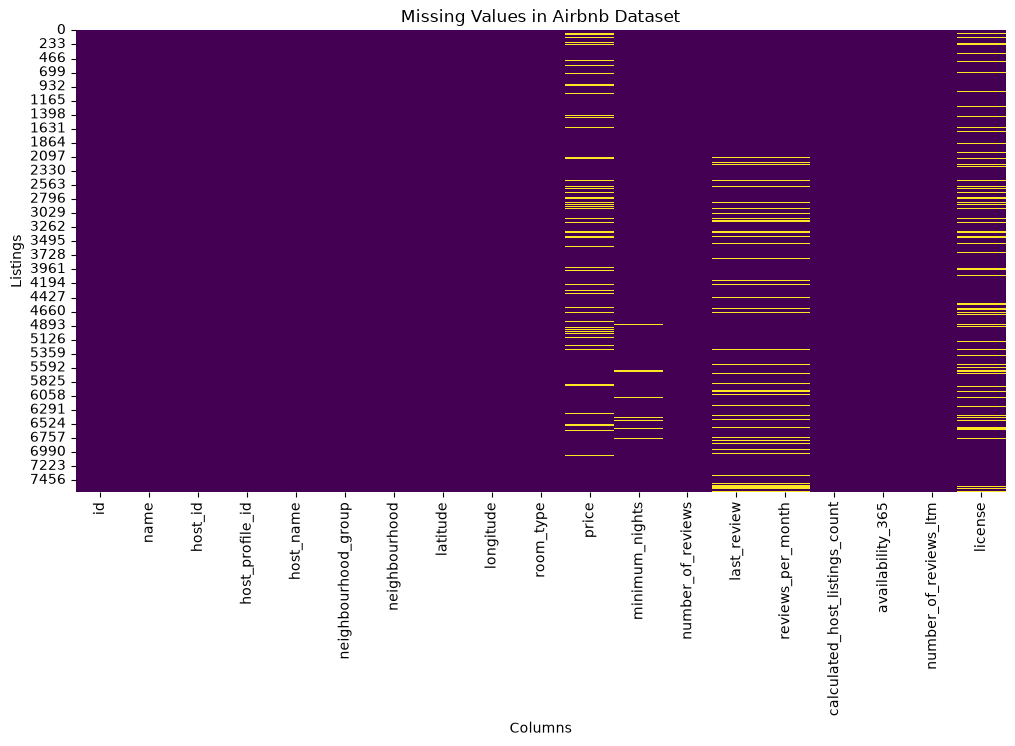

In [7]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values in Airbnb Dataset")
plt.xlabel("Columns")
plt.ylabel("Listings")

plt.show()

In [8]:
df.describe()

,id,host_id,host_profile_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
count,7.657000e+03,7.657000e+03,7.657000e+03,7657.000000,7657.000000,6525.000000,7567.000000,7657.000000,6742.000000,7657.000000,7657.000000,7657.000000
mean,8.622572e+17,2.338660e+16,1.482581e+18,47.626067,-122.334635,277.058697,10.351262,83.126028,2.198937,17.519786,205.693875,16.219146
std,6.566686e+17,1.984001e+17,5.375912e+16,0.049984,0.033818,333.690264,20.628668,131.228433,2.115950,42.115724,125.864431,21.306976
min,6.606000e+03,1.618000e+03,1.462506e+18,47.497490,-122.419478,23.000000,1.000000,0.000000,0.010000,1.000000,0.000000,0.000000
25%,4.946709e+07,2.136237e+07,1.462883e+18,47.599600,-122.357820,142.000000,1.000000,5.000000,0.640000,1.000000,88.000000,1.000000
50%,9.697998e+17,8.856686e+07,1.465817e+18,47.624434,-122.333000,225.000000,2.000000,32.000000,1.810000,2.000000,230.000000,9.000000
75%,1.487405e+18,3.769420e+08,1.469839e+18,47.664340,-122.310970,334.000000,30.000000,106.000000,3.170000,11.000000,327.000000,25.000000
max,1.778062e+18,1.769717e+18,1.775724e+18,47.734010,-122.241160,9803.000000,730.000000,1701.000000,48.570000,219.000000,365.000000,425.000000



## 3. Duplicate Detection and Removal

Duplicate records were checked using Pandas `duplicated()` function.

The dataset was also checked for duplicate listing IDs to ensure that each listing was unique.

### Results

- Duplicate Rows: 0
- Duplicate Listing IDs: 0

No duplicate records were found. Therefore, no rows needed to be removed.

This ensures that every listing is represented only once in the dataset.


In [9]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


In [10]:
duplicate_ids = df["id"].duplicated().sum()

print("Duplicate Listing IDs:", duplicate_ids)

Duplicate Listing IDs: 0


In [11]:
print("Unique Room Types:")
print(df["room_type"].unique())

print("\nRoom Type Counts:")
print(df["room_type"].value_counts())

Unique Room Types:
<StringArray>
['Entire home/apt', 'Private room', 'Shared room', 'Hotel room']
Length: 4, dtype: str

Room Type Counts:
room_type
Entire home/apt    6221
Private room       1361
Hotel room           46
Shared room          29
Name: count, dtype: int64


In [12]:
print("Neighbourhood Groups:")
print(df["neighbourhood_group"].unique())

print("\nNumber of Unique Neighbourhoods:")
print(df["neighbourhood"].nunique())

Neighbourhood Groups:
<StringArray>
['Other neighborhoods',             'Ballard',             'Cascade',
        'Capitol Hill',      'Rainier Valley',            'Magnolia',
        'West Seattle',            'Downtown',         'Beacon Hill',
           'Lake City',        'Central Area', 'University District',
            'Delridge',          'Queen Anne',           'Northgate',
         'Seward Park',            'Interbay']
Length: 17, dtype: str

Number of Unique Neighbourhoods:
87


In [13]:
print("Room Type Formatting Issues:",
      (df["room_type"] != df["room_type"].str.strip()).sum())

print("Neighbourhood Formatting Issues:",
      (df["neighbourhood"] != df["neighbourhood"].str.strip()).sum())

print("Neighbourhood Group Formatting Issues:",
      (df["neighbourhood_group"] != df["neighbourhood_group"].str.strip()).sum())

Room Type Formatting Issues: 0
Neighbourhood Formatting Issues: 0
Neighbourhood Group Formatting Issues: 0


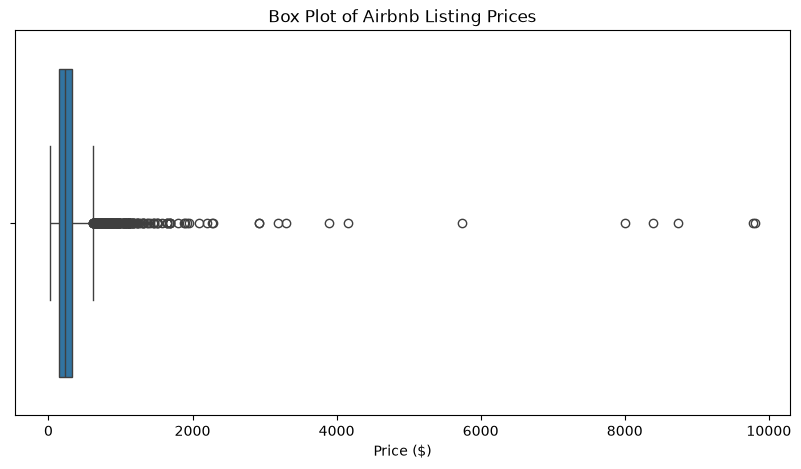

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["price"])

plt.title("Box Plot of Airbnb Listing Prices")
plt.xlabel("Price ($)")

plt.show()


## 4. Outlier Detection and Treatment

Outliers were identified in numerical columns using the Interquartile Range (IQR) method.

### IQR Method

The IQR is calculated as:

IQR = Q3 - Q1

Lower Bound = Q1 - (1.5 × IQR)

Upper Bound = Q3 + (1.5 × IQR)

Values outside these boundaries were considered potential outliers.

### Columns Analyzed

1. Price
2. Minimum Nights
3. Reviews Per Month

### Treatment

Instead of removing extreme values, IQR-based capping was applied using Pandas `clip()` function.

This approach preserves all listing records while limiting the influence of extreme numerical values.

The cleaned values were stored in separate columns ending with `_cleaned`.


In [15]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 142.0
Q3: 334.0
IQR: 192.0
Lower Bound: -146.0
Upper Bound: 622.0


In [16]:
price_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Number of Price Outliers:", len(price_outliers))
print("Percentage of Price Outliers:",
      round((len(price_outliers) / df["price"].notnull().sum()) * 100, 2), "%")

Number of Price Outliers: 329
Percentage of Price Outliers: 5.04 %


In [17]:
df["price"].nlargest(10)

5879    9803.0
5508    9774.0
5393    8734.0
6811    8386.0
7576    8000.0
6968    5740.0
6345    4162.0
6338    3897.0
7549    3304.0
6983    3187.0
Name: price, dtype: float64

In [18]:
top_expensive = df.nlargest(10, "price")

top_expensive[[
    "name",
    "neighbourhood",
    "room_type",
    "price",
    "minimum_nights"
]]

,name,neighbourhood,room_type,price,minimum_nights
5879,Luxury & Spacious Home~AC~Gym~Dogs OK~Lake Access,Wallingford,Entire home/apt,9803.0,1.0
5508,Spacious Home~Parking~Pike Place& Space Needle...,North Queen Anne,Entire home/apt,9774.0,1.0
5393,2m Exclusive Luxury Home in Green Lake | AC&Ga...,Wallingford,Entire home/apt,8734.0,30.0
6811,Excellent Location in Belltown!,Belltown,Entire home/apt,8386.0,100.0
7576,Bayside Retreat | 3BR Home w/ Hot Tub & Fire Pit,Seward Park,Entire home/apt,8000.0,1.0
6968,Brighton Guesthouse,Brighton,Entire home/apt,5740.0,1.0
6345,67 foot Italian Yacht your 2 private suites,South Lake Union,Private room,4162.0,30.0
6338,Luxury Downtown Seattle | Iconic Views | 4 Units,Central Business District,Hotel room,3897.0,1.0
7549,Queen Anne 12BR/8BA | AC I Easy Driveway Parking,West Queen Anne,Entire home/apt,3304.0,2.0
6983,Stylish 2-Bedroom Hotel Suite w/ Breakfast,Pioneer Square,Private room,3187.0,1.0


In [19]:
df["price_cleaned"] = df["price"].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Original Maximum Price:", df["price"].max())
print("Capped Maximum Price:", df["price_cleaned"].max())

Original Maximum Price: 9803.0
Capped Maximum Price: 622.0


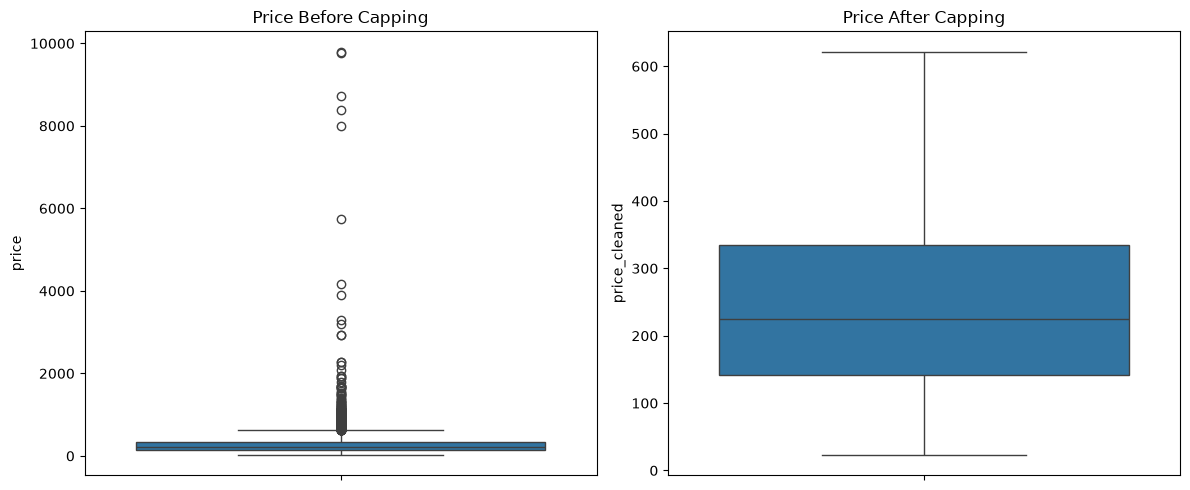

In [20]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["price"])
plt.title("Price Before Capping")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["price_cleaned"])
plt.title("Price After Capping")

plt.tight_layout()
plt.show()

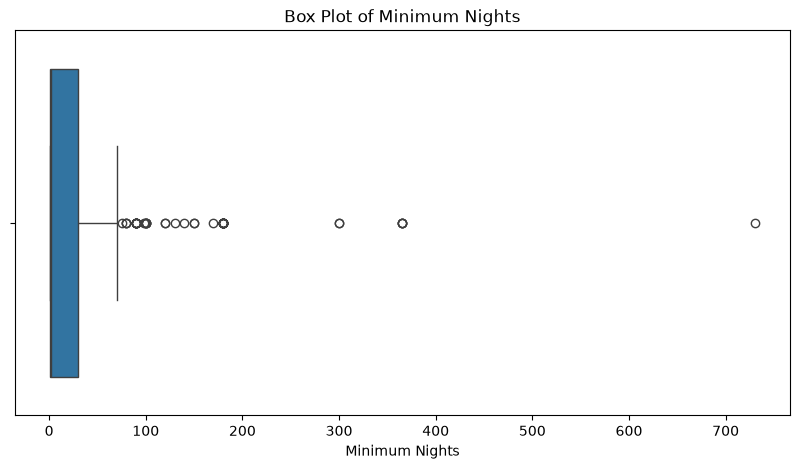

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["minimum_nights"])

plt.title("Box Plot of Minimum Nights")
plt.xlabel("Minimum Nights")

plt.show()

In [22]:
Q1_min = df["minimum_nights"].quantile(0.25)
Q3_min = df["minimum_nights"].quantile(0.75)

IQR_min = Q3_min - Q1_min

lower_min = Q1_min - 1.5 * IQR_min
upper_min = Q3_min + 1.5 * IQR_min

print("Q1:", Q1_min)
print("Q3:", Q3_min)
print("IQR:", IQR_min)
print("Lower Bound:", lower_min)
print("Upper Bound:", upper_min)

Q1: 1.0
Q3: 30.0
IQR: 29.0
Lower Bound: -42.5
Upper Bound: 73.5


In [23]:
min_night_outliers = df[
    (df["minimum_nights"] < lower_min) |
    (df["minimum_nights"] > upper_min)
]

print("Number of Minimum Nights Outliers:", len(min_night_outliers))

print("Percentage of Outliers:",
      round(len(min_night_outliers) / df["minimum_nights"].notnull().sum() * 100, 2), "%")

Number of Minimum Nights Outliers: 53
Percentage of Outliers: 0.7 %


In [24]:
df["minimum_nights"].nlargest(10)

3928    730.0
5723    365.0
5725    365.0
5840    365.0
6771    365.0
1336    300.0
2561    300.0
67      180.0
161     180.0
417     180.0
Name: minimum_nights, dtype: float64

In [25]:
df["minimum_nights_cleaned"] = df["minimum_nights"].clip(
    lower=lower_min,
    upper=upper_min
)

print("Original Maximum:", df["minimum_nights"].max())
print("Capped Maximum:", df["minimum_nights_cleaned"].max())

Original Maximum: 730.0
Capped Maximum: 73.5


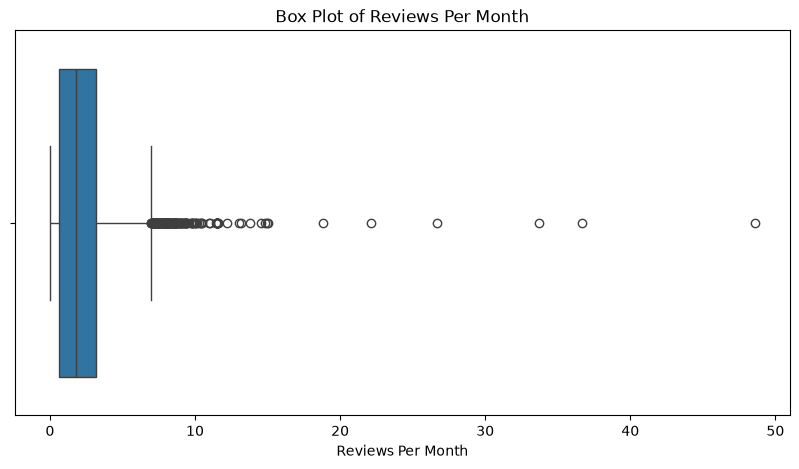

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["reviews_per_month"])

plt.title("Box Plot of Reviews Per Month")
plt.xlabel("Reviews Per Month")

plt.show()

In [27]:
Q1_reviews = df["reviews_per_month"].quantile(0.25)
Q3_reviews = df["reviews_per_month"].quantile(0.75)

IQR_reviews = Q3_reviews - Q1_reviews

lower_reviews = Q1_reviews - 1.5 * IQR_reviews
upper_reviews = Q3_reviews + 1.5 * IQR_reviews

print("Q1:", Q1_reviews)
print("Q3:", Q3_reviews)
print("IQR:", IQR_reviews)
print("Lower Bound:", lower_reviews)
print("Upper Bound:", upper_reviews)

Q1: 0.64
Q3: 3.17
IQR: 2.53
Lower Bound: -3.155
Upper Bound: 6.965


In [28]:
review_outliers = df[
    (df["reviews_per_month"] < lower_reviews) |
    (df["reviews_per_month"] > upper_reviews)
]

print("Number of Review Outliers:", len(review_outliers))

print("Percentage of Outliers:",
      round(len(review_outliers) / df["reviews_per_month"].notnull().sum() * 100, 2), "%")

Number of Review Outliers: 172
Percentage of Outliers: 2.55 %


In [29]:
df["reviews_per_month"].nlargest(10)

4383    48.57
4384    36.68
6436    33.73
6155    26.67
6458    22.15
4873    18.79
7026    15.00
1324    14.96
6878    14.83
7260    14.55
Name: reviews_per_month, dtype: float64

In [30]:
df["reviews_per_month_cleaned"] = df["reviews_per_month"].clip(
    lower=lower_reviews,
    upper=upper_reviews
)

print("Original Maximum:", df["reviews_per_month"].max())
print("Capped Maximum:", df["reviews_per_month_cleaned"].max())

Original Maximum: 48.57
Capped Maximum: 6.965


In [31]:
print("Price:", df["price"].isnull().sum())
print("Minimum Nights:", df["minimum_nights"].isnull().sum())
print("Reviews Per Month:", df["reviews_per_month"].isnull().sum())

Price: 1132
Minimum Nights: 90
Reviews Per Month: 915


In [32]:
price_median = df["price"].median()

df["price"] = df["price"].fillna(price_median)

print("Missing Price Values After Cleaning:",
      df["price"].isnull().sum())

print("Median Price Used:", price_median)

Missing Price Values After Cleaning: 0
Median Price Used: 225.0


In [33]:
minimum_nights_median = df["minimum_nights"].median()

df["minimum_nights"] = df["minimum_nights"].fillna(
    minimum_nights_median
)

print("Missing Minimum Nights After Cleaning:",
      df["minimum_nights"].isnull().sum())

print("Median Used:", minimum_nights_median)

Missing Minimum Nights After Cleaning: 0
Median Used: 2.0


In [34]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

print("Missing Values After Cleaning:",
      df["reviews_per_month"].isnull().sum())

print("Zero Values:",
      (df["reviews_per_month"] == 0).sum())

Missing Values After Cleaning: 0
Zero Values: 915


In [35]:
df[df["last_review"].isnull()]["number_of_reviews"].value_counts()

number_of_reviews
0    915
Name: count, dtype: int64

In [36]:
df["license"] = df["license"].fillna("Not Provided")

print("Missing License Values After Cleaning:",
      df["license"].isnull().sum())

print("Not Provided Count:",
      (df["license"] == "Not Provided").sum())

Missing License Values After Cleaning: 0
Not Provided Count: 1244


In [37]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
id                                   0
name                                 0
host_id                              0
host_profile_id                      0
host_name                            0
neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                        915
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
number_of_reviews_ltm                0
license                              0
price_cleaned                     1132
minimum_nights_cleaned              90
reviews_per_month_cleaned          915
dtype: int64

Total Missing Values: 3052


In [38]:
df["price_cleaned"] = df["price"].clip(
    lower=lower_bound,
    upper=upper_bound
)

df["minimum_nights_cleaned"] = df["minimum_nights"].clip(
    lower=lower_min,
    upper=upper_min
)

df["reviews_per_month_cleaned"] = df["reviews_per_month"].clip(
    lower=lower_reviews,
    upper=upper_reviews
)

print("Missing Price Cleaned:",
      df["price_cleaned"].isnull().sum())

print("Missing Minimum Nights Cleaned:",
      df["minimum_nights_cleaned"].isnull().sum())

print("Missing Reviews Per Month Cleaned:",
      df["reviews_per_month_cleaned"].isnull().sum())

Missing Price Cleaned: 0
Missing Minimum Nights Cleaned: 0
Missing Reviews Per Month Cleaned: 0


In [39]:
print("Total Missing Values:", df.isnull().sum().sum())

print("\nColumns with Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Total Missing Values: 915

Columns with Missing Values:
last_review    915
dtype: int64


In [40]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].nunique(), "unique values")

Categorical Columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review', 'license']

name:
7413 unique values

host_name:
2105 unique values

neighbourhood_group:
17 unique values

neighbourhood:
87 unique values

room_type:
4 unique values

last_review:
837 unique values

license:
4443 unique values


C:\Users\sugan\AppData\Local\Temp\ipykernel_4888\536501795.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(



## 5. Categorical Data Encoding

Categorical variables were converted into numerical representations using One-Hot Encoding.

This technique creates separate binary columns for each category.

### Columns Selected

1. `room_type` - 4 unique categories
2. `neighbourhood_group` - 17 unique categories

### Encoding Process

Pandas `get_dummies()` was used to convert these categorical columns into numerical columns containing 0 and 1 values.

- 1 represents the presence of a category.
- 0 represents the absence of a category.

A total of 21 encoded columns were created.

Other descriptive columns, such as listing names, host names, neighbourhoods, and license identifiers, were retained in their original form.


In [41]:
df = pd.get_dummies(
    df,
    columns=["room_type"],
    prefix="room_type",
    dtype=int
)

df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,price,...,availability_365,number_of_reviews_ltm,license,price_cleaned,minimum_nights_cleaned,reviews_per_month_cleaned,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,6606,"Fab, private seattle urban cottage!",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65444,-122.33629,113.0,...,177,0,str-opli-19-002622,113.0,30.0,0.77,1,0,0,0
1,9419,Glorious sun room w/ memory foambed,30559,1462507132280540713,Angielena,Other neighborhoods,Georgetown,47.55017,-122.31937,86.0,...,308,2,Exempt,86.0,2.0,1.13,0,0,1,0
2,9596,"the down home , spacious, central and fab!",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65608,-122.33602,225.0,...,0,0,STR -OPLI-19-002622,225.0,30.0,0.52,1,0,0,0
3,11012,"the orange house, quiet 'n central",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65405,-122.33744,204.0,...,178,0,str-opli-19-002622,204.0,30.0,0.48,1,0,0,0
4,25002,Beautiful Private Spot in North Ballard,102684,1462509654203779028,Amanda,Ballard,Whittier Heights,47.67947,-122.37196,121.0,...,218,60,STR-OPLI-19-002617,121.0,2.0,6.00,1,0,0,0


In [42]:
df = pd.get_dummies(
    df,
    columns=["neighbourhood_group"],
    prefix="neighbourhood",
    dtype=int
)

print("Encoding Completed!")

df.head()

Encoding Completed!


,id,name,host_id,host_profile_id,host_name,neighbourhood,latitude,longitude,price,minimum_nights,...,neighbourhood_Interbay,neighbourhood_Lake City,neighbourhood_Magnolia,neighbourhood_Northgate,neighbourhood_Other neighborhoods,neighbourhood_Queen Anne,neighbourhood_Rainier Valley,neighbourhood_Seward Park,neighbourhood_University District,neighbourhood_West Seattle
0,6606,"Fab, private seattle urban cottage!",14942,1462506762321392885,Joyce,Wallingford,47.65444,-122.33629,113.0,30.0,...,0,0,0,0,1,0,0,0,0,0
1,9419,Glorious sun room w/ memory foambed,30559,1462507132280540713,Angielena,Georgetown,47.55017,-122.31937,86.0,2.0,...,0,0,0,0,1,0,0,0,0,0
2,9596,"the down home , spacious, central and fab!",14942,1462506762321392885,Joyce,Wallingford,47.65608,-122.33602,225.0,30.0,...,0,0,0,0,1,0,0,0,0,0
3,11012,"the orange house, quiet 'n central",14942,1462506762321392885,Joyce,Wallingford,47.65405,-122.33744,204.0,30.0,...,0,0,0,0,1,0,0,0,0,0
4,25002,Beautiful Private Spot in North Ballard,102684,1462509654203779028,Amanda,Whittier Heights,47.67947,-122.37196,121.0,2.0,...,0,0,0,0,0,0,0,0,0,0


In [43]:
encoded_columns = [
    col for col in df.columns
    if col.startswith("room_type_")
    or col.startswith("neighbourhood_")
]

print("Encoded Columns:")
print(encoded_columns)

print("\nTotal Encoded Columns:", len(encoded_columns))

Encoded Columns:
['room_type_Entire home/apt', 'room_type_Hotel room', 'room_type_Private room', 'room_type_Shared room', 'neighbourhood_Ballard', 'neighbourhood_Beacon Hill', 'neighbourhood_Capitol Hill', 'neighbourhood_Cascade', 'neighbourhood_Central Area', 'neighbourhood_Delridge', 'neighbourhood_Downtown', 'neighbourhood_Interbay', 'neighbourhood_Lake City', 'neighbourhood_Magnolia', 'neighbourhood_Northgate', 'neighbourhood_Other neighborhoods', 'neighbourhood_Queen Anne', 'neighbourhood_Rainier Valley', 'neighbourhood_Seward Park', 'neighbourhood_University District', 'neighbourhood_West Seattle']

Total Encoded Columns: 21



## 6. Date Column Conversion

The `last_review` column originally contained date values stored as text.

The Pandas `to_datetime()` function was used to convert the column into a proper datetime data type.

The `errors="coerce"` parameter ensures that invalid date values are converted into missing values instead of causing errors.

### Result

- Data Type: datetime64[us]
- Missing Dates: 915

The missing dates were retained because these listings had received zero reviews.


In [44]:
df["last_review"] = pd.to_datetime(
    df["last_review"],
    errors="coerce"
)

print("Data Type:", df["last_review"].dtype)

print("Missing Dates:", df["last_review"].isnull().sum())

Data Type: datetime64[us]
Missing Dates: 915


In [45]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes.value_counts())

print("\nFirst 5 Rows:")
df.head()

Dataset Shape:

 (7657, 41)

Data Types:
int64             28
float64            8
str                4
datetime64[us]     1
Name: count, dtype: int64

First 5 Rows:


,id,name,host_id,host_profile_id,host_name,neighbourhood,latitude,longitude,price,minimum_nights,...,neighbourhood_Interbay,neighbourhood_Lake City,neighbourhood_Magnolia,neighbourhood_Northgate,neighbourhood_Other neighborhoods,neighbourhood_Queen Anne,neighbourhood_Rainier Valley,neighbourhood_Seward Park,neighbourhood_University District,neighbourhood_West Seattle
0,6606,"Fab, private seattle urban cottage!",14942,1462506762321392885,Joyce,Wallingford,47.65444,-122.33629,113.0,30.0,...,0,0,0,0,1,0,0,0,0,0
1,9419,Glorious sun room w/ memory foambed,30559,1462507132280540713,Angielena,Georgetown,47.55017,-122.31937,86.0,2.0,...,0,0,0,0,1,0,0,0,0,0
2,9596,"the down home , spacious, central and fab!",14942,1462506762321392885,Joyce,Wallingford,47.65608,-122.33602,225.0,30.0,...,0,0,0,0,1,0,0,0,0,0
3,11012,"the orange house, quiet 'n central",14942,1462506762321392885,Joyce,Wallingford,47.65405,-122.33744,204.0,30.0,...,0,0,0,0,1,0,0,0,0,0
4,25002,Beautiful Private Spot in North Ballard,102684,1462509654203779028,Amanda,Whittier Heights,47.67947,-122.37196,121.0,2.0,...,0,0,0,0,0,0,0,0,0,0


In [46]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nData Type Counts:")
print(df.dtypes.value_counts())

Number of Rows: 7657
Number of Columns: 41

Data Type Counts:
int64             28
float64            8
str                4
datetime64[us]     1
Name: count, dtype: int64


In [47]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Listing IDs:", df["id"].duplicated().sum())

Duplicate Rows: 0
Duplicate Listing IDs: 0



## 7. Before and After Cleaning Comparison

The original and cleaned datasets were compared to evaluate the effectiveness of the preprocessing operations.

### Dataset Comparison

| Metric | Before Cleaning | After Cleaning |
|---|---:|---:|
| Rows | 7,657 | 7,657 |
| Columns | 19 | 41 |
| Missing Values | 4,296 | 915 |
| Duplicate Rows | 0 | 0 |

### Numerical Statistics Comparison

| Column | Original Maximum | Cleaned Maximum |
|---|---:|---:|
| Price | 9,803 | 622 |
| Minimum Nights | 730 | 74 |
| Reviews Per Month | 48.57 | 6.965 |

### Observations

- All 7,657 listing records were preserved.
- Missing values were reduced from 4,296 to 915.
- Extreme numerical values were capped using the IQR method.
- Categorical variables were converted into numerical representations.
- Duplicate records were not found.

The comparison shows that the preprocessing operations improved the consistency and usability of the dataset.


In [48]:
original_df = pd.read_csv("raw_dataset.csv")

print("BEFORE CLEANING")
print("Rows:", original_df.shape[0])
print("Columns:", original_df.shape[1])
print("Missing Values:", original_df.isnull().sum().sum())

print("\nAFTER CLEANING")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

BEFORE CLEANING
Rows: 7657
Columns: 19
Missing Values: 4296

AFTER CLEANING
Rows: 7657
Columns: 41
Missing Values: 915
Duplicate Rows: 0


In [49]:
print("ORIGINAL DATA STATISTICS")
print(original_df[[
    "price",
    "minimum_nights",
    "reviews_per_month"
]].describe())

print("\nCLEANED DATA STATISTICS")
print(df[[
    "price_cleaned",
    "minimum_nights_cleaned",
    "reviews_per_month_cleaned"
]].describe())

ORIGINAL DATA STATISTICS
             price  minimum_nights  reviews_per_month
count  6525.000000     7567.000000        6742.000000
mean    277.058697       10.351262           2.198937
std     333.690264       20.628668           2.115950
min      23.000000        1.000000           0.010000
25%     142.000000        1.000000           0.640000
50%     225.000000        2.000000           1.810000
75%     334.000000       30.000000           3.170000
max    9803.000000      730.000000          48.570000

CLEANED DATA STATISTICS


       price_cleaned  minimum_nights_cleaned  reviews_per_month_cleaned
count    7657.000000             7657.000000                7657.000000
mean      249.916547                9.586196                   1.877669
std       137.954855               13.750901                   1.785968
min        23.000000                1.000000                   0.000000
25%       157.000000                1.000000                   0.300000
50%       225.000000                2.000000                   1.480000
75%       308.000000               30.000000                   2.940000
max       622.000000               73.500000                   6.965000


In [50]:
df["minimum_nights_cleaned"] = (
    df["minimum_nights_cleaned"].round().astype(int)
)

print("Minimum Nights Data Type:",
      df["minimum_nights_cleaned"].dtype)

print("Maximum Minimum Nights:",
      df["minimum_nights_cleaned"].max())

Minimum Nights Data Type: int64
Maximum Minimum Nights: 74



## 8. Exporting the Cleaned Dataset

After completing the data cleaning and preprocessing operations, the final dataset was exported into CSV format using Pandas `to_csv()` function.

### Export Details

- Output File: `cleaned_dataset.csv`
- Total Rows: 7,657
- Total Columns: 41
- Export Format: CSV

The exported file was loaded again to verify that the data was saved successfully.

The verification confirmed that the exported dataset retained its expected dimensions of 7,657 rows and 41 columns.


In [51]:
df.to_csv("cleaned_dataset.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [52]:
cleaned_check = pd.read_csv("cleaned_dataset.csv")

print("Exported Dataset Shape:", cleaned_check.shape)

print("File Loaded Successfully:",
      cleaned_check.shape == df.shape)

Exported Dataset Shape: (7657, 41)
File Loaded Successfully: True



## 9. Conclusion

This project successfully demonstrated the process of cleaning and preprocessing a real-world Airbnb listings dataset using Python.

The major data preprocessing operations included:

- Identifying and handling missing values.
- Checking for duplicate records.
- Detecting and capping numerical outliers using the IQR method.
- Applying One-Hot Encoding to categorical variables.
- Converting date columns into appropriate datetime formats.
- Comparing original and cleaned dataset statistics.
- Exporting and verifying the final cleaned dataset.

The final dataset contains 7,657 rows and 41 columns.

The cleaning process improved data consistency while preserving all listing records. The resulting dataset is now better prepared for further exploratory data analysis and machine learning tasks.

**Output:** `cleaned_dataset.csv`
